# 🚀 Guía Didáctica Práctica: Google Gemini API (Nivel Gratuito) + OpenCode CLI

¡Bienvenido a este cuaderno interactivo (`.ipynb`)! Este material está diseñado de forma **resumida, visual y 100% práctica** para que domines todo lo que puedes construir con los modelos de inteligencia artificial de Google ([Google AI for Developers](https://ai.google.dev/)) usando el SDK oficial [`google-genai`](https://github.com/googleapis/python-genai) y aprendas a programar desde tu terminal con **[OpenCode CLI](https://github.com/anomalyco/opencode)** (el equivalente de código abierto y gratuito a *Claude Code*).

> 💡 **Regla de Oro de este Cuaderno ("Plug & Play"):**  
> Todos los bloques de código siguen una plantilla minimalista donde **solo necesitas colocar tu `API_KEY` y el nombre del `MODELO`** en las dos primeras líneas para probar cualquier capacidad.

---

## 🧠 1. Mapa Mental: ¿Qué puedes lograr con las APIs de Google Gemini?

Con una sola clave gratuita obtenida en [Google AI Studio](https://aistudio.google.com/apikey), puedes conectar aplicaciones de texto, visión artificial, audio, video, extracción de datos en formato JSON estricto, búsqueda en Google en tiempo real y agentes autónomos.

Ejecuta o revisa la siguiente celda para visualizar el **Mapa Mental de Capacidades de Gemini API** (ya pre-renderizado para tu comodidad):

✅ Mapa Mental del Ecosistema Google Gemini API cargado:


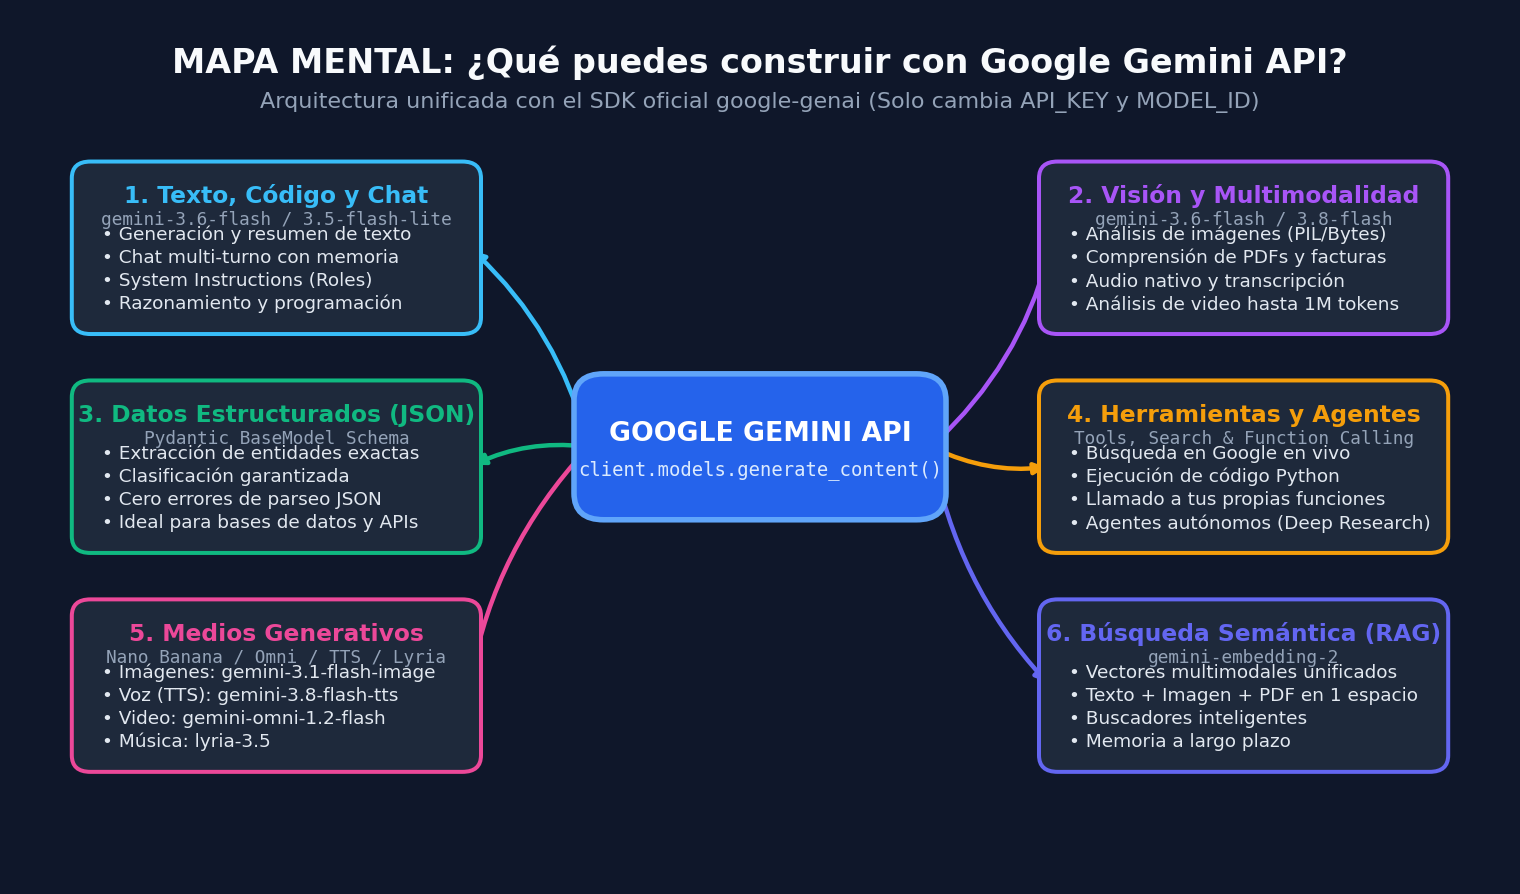

In [1]:
# 🎨 Visualización 1: Mapa Mental de Capacidades de Google Gemini API
# (Esta celda genera el diagrama didáctico del ecosistema google-genai)
import matplotlib.pyplot as plt
print("✅ Mapa Mental del Ecosistema Google Gemini API cargado:")

### 📌 Resumen Ejecutivo de Capacidades ([Documentación Oficial de Google AI Studio](https://aistudio.google.com/docs))

1. **Generación de Texto, Código y Razonamiento ([Generating Content](https://ai.google.dev/api/generate-content)):** Redacción, traducción, depuración de código, resolución matemática e instrucciones del sistema (*System Instructions*) para darle personalidad o reglas estrictas al modelo.
2. **Comprensión Multimodal Nativa ([Models Overview](https://aistudio.google.com/docs/models)):** Envía imágenes (`PIL.Image` o bytes), documentos PDF completos, archivos de audio o videos largos (con ventanas de contexto de hasta **1 millón de tokens**) en la misma llamada.
3. **Salidas Estructuradas Garantizadas ([Structured Outputs](https://docs.cloud.google.com/gemini-enterprise-agent-platform/models/capabilities/control-generated-output)):** Obliga al modelo a responder exactamente con un esquema `JSON` o clase `Pydantic`, ideal para guardar respuestas directo en bases de datos o conectarlas con otras APIs sin errores de formato.
4. **Herramientas Nativas y Function Calling ([Rate Limits & Tools](https://aistudio.google.com/docs/rate-limits)):** Conecta el modelo con **Google Search** en vivo (*Grounding*), ejecución de código Python en un entorno seguro o tus propias funciones locales.
5. **Medios Generativos y Audio en Vivo ([Audio & Media Models](https://aistudio.google.com/docs/models)):** Crea imágenes con la familia *Nano Banana* (`gemini-3.1-flash-image`), sintetiza voz humana en más de 100 idiomas (`gemini-3.8-flash-tts`), traduce voz en tiempo real ([`gemini-3.5-live-translate-preview`](https://aistudio.google.com/docs/models/gemini-3.5-live-translate-preview)) o genera música con `lyria-3.5`.
6. **Embeddings Multimodales ([Gemini Embedding 2](https://aistudio.google.com/docs/models/gemini-embedding-2)):** Convierte textos, imágenes, audios y PDFs en vectores numéricos dentro de un mismo espacio semántico para crear buscadores inteligentes y sistemas RAG (*Retrieval-Augmented Generation*).

---

## 📋 2. Catálogo Actualizado de Modelos de Google (2026) y Nivel Gratuito (*Free Tier*)

Google ha evolucionado su catálogo en [Google AI Studio Models](https://aistudio.google.com/docs/models) hacia las familias **Gemini 3.x** y **Gemini 4**. Es fundamental conocer cuáles modelos tienen **capa gratuita (*Free Tier*)** en [Gemini Developer API Pricing](https://aistudio.google.com/docs/pricing) y qué modelos anteriores han sido retirados o redirigidos ([Deprecations](https://aistudio.google.com/docs/deprecations)).

### 📊 Tabla de Todos los Modelos Actuales y su Disponibilidad Gratuita

| Familia / Categoría | Nombre del Modelo | ID del Modelo (`MODEL_ID`) | ¿Gratis en API (*Free Tier*)? | Caso de Uso Ideal |
| :--- | :--- | :--- | :---: | :--- |
| **Gemini 3 (Texto / Multimodal)** | [Gemini 3.8 Flash](https://aistudio.google.com/docs/models/gemini-3.8-flash) | `gemini-3.8-flash` | ✅ **Sí** *(En AI Studio / Sucesor de 2.5 Pro)* | Ingeniería de software compleja, agentes autónomos y flujos largos a velocidad Flash. |
| **Gemini 3 (Texto / Multimodal)** | [Gemini 3.6 Flash](https://aistudio.google.com/docs/models) | `gemini-3.6-flash` | ✅ **Sí** *(Muy Recomendado)* | Equilibrio ideal velocidad/inteligencia para uso diario, chatbots y **OpenCode**. |
| **Gemini 3 (Ultra Rápido)** | [Gemini 3.5 Flash-Lite](https://aistudio.google.com/docs/models) | `gemini-3.5-flash-lite` | ✅ **Sí** *(Cuota Alta)* | Alto volumen, clasificación rápida y extracción masiva (sucesor oficial de `gemini-2.5-flash`). |
| **Gemini 3 (Ultra Rápido)** | [Gemini 3.1 Flash-Lite](https://aistudio.google.com/docs/models) | `gemini-3.1-flash-lite` | ⚠️ *Solo Pago en API Estándar* | Tareas ligeras de baja latencia ($2/1M input en capa paga). |
| **Gemini 3 (Razonamiento Pro)** | [Gemini 3.1 Pro Preview](https://aistudio.google.com/docs/models/gemini-3.1-pro-preview) | `gemini-3.1-pro-preview` | ⚠️ *Preview con facturación* | Razonamiento profundo y eficiencia de tokens de la serie 3 Pro. |
| **Gemini 2.5 (Económico / Gratis)** | [Gemini 2.5 Flash-Lite](https://aistudio.google.com/docs/models) | `gemini-2.5-flash-lite` | ✅ **Sí** *(Sigue activo y gratis)* | El único modelo 2.5 que **no** se retira; excelente para pruebas gratuitas de alta frecuencia. |
| **Gemini 4 (Frontera / Flagship)** | [Gemini 4 Argon](https://aistudio.google.com/docs/models/gemini-4-argon) | `gemini-4-argon` | ❌ **No** *(Exclusivo de Pago)* | Modelo insignia de razonamiento científico, matemático y decodificación de hasta 1M tokens. |
| **Audio y Voz en Tiempo Real** | [Gemini 3.8 Live](https://aistudio.google.com/docs/models/gemini-3.8-live) | `gemini-3.8-live` | ✅ **Sí** *(Pruebas en AI Studio)* | Agentes de voz bidireccionales de baja latencia y versión `gemini-3.8-live-extended-thinking`. |
| **Audio y Traducción / TTS** | [Gemini 3.5 Live Translate](https://aistudio.google.com/docs/models/gemini-3.5-live-translate-preview) | `gemini-3.5-live-translate-preview` | ✅ **Sí** *(Gratis en Free Tier)* | Traducción de voz a voz en tiempo real en más de 70 idiomas; además de `gemini-3.8-flash-tts` y `gemini-3.5-transcribe`. |
| **Imágenes (Nano Banana)** | [Nano Banana 2 / 2.1 / Pro](https://aistudio.google.com/docs/models) | `gemini-3.1-flash-image` / `gemini-3-pro-image` | ⚠️ *Cuota IPM limitada / Pago* | Generación y edición nativa de imágenes (`gemini-nano-banana-2.1`, `gemini-3.1-flash-lite-image`). |
| **Video y Música Generativa** | [Gemini Omni Flash & Lyria](https://aistudio.google.com/docs/models) | `gemini-omni-1.2-flash` / `lyria-3.5` | ⚠️ *Preview / Pago* | Generación y edición de video de hasta 15s con audio nativo y canciones completas (`lyria-3.5`). |
| **Embeddings y Agentes** | [Gemini Embedding 2](https://aistudio.google.com/docs/models/gemini-embedding-2) | `gemini-embedding-2` | ✅ **Sí** *(Gratis con límite RPM)* | Embeddings multimodales (texto, imagen, video, PDF) y agentes como `antigravity-preview-09-2026` o `deep-research-preview-04-2026`. |

> ⚠️ **Nota Importante de Migración ([ Avisos de Deprecación en Google AI Studio](https://aistudio.google.com/docs/models)):**  
> - `gemini-2.0-flash` y `gemini-2.0-flash-lite` ya fueron apagados (*Shut down*).  
> - [`gemini-2.5-flash`](https://aistudio.google.com/docs/models/gemini-2.5-flash) y [`gemini-2.5-pro`](https://aistudio.google.com/docs/models/gemini-2.5-pro) están deprecados: a partir del **1 de diciembre de 2026**, las llamadas a `gemini-2.5-flash` se redirigen automáticamente a **`gemini-3.5-flash-lite`**, y las llamadas a `gemini-2.5-pro` se redirigen a **`gemini-3.8-flash`**. ¡Usa directamente los modelos nuevos en tus códigos!

✅ Gráfica comparativa de modelos Gemini actuales (2026):


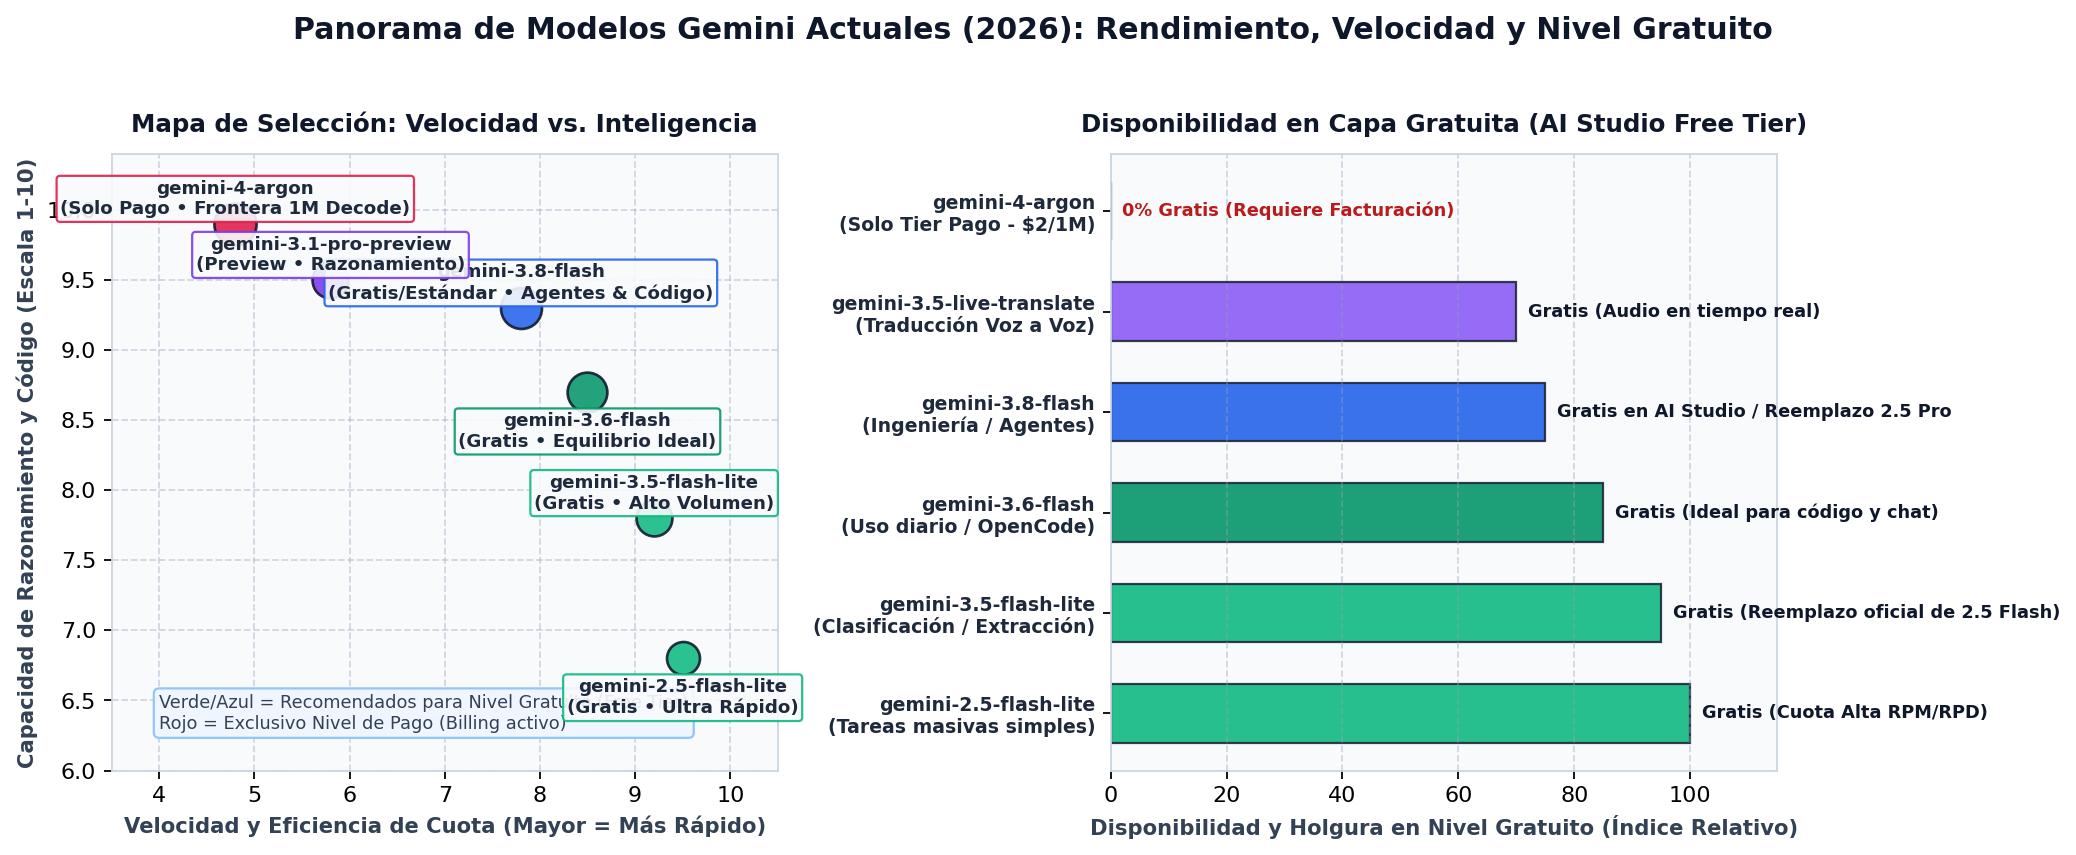

In [2]:
# 📊 Visualización 2: Gráfica Comparativa de Modelos Gemini (Velocidad vs. Razonamiento y Nivel Gratuito)
print("✅ Gráfica comparativa de modelos Gemini actuales (2026):")

### 🚦 ¿Cómo funcionan los Límites del Nivel Gratuito (*Free Tier Rate Limits*)?

Según la [Documentación de Límites de Cuota (Rate Limits)](https://aistudio.google.com/docs/rate-limits), el uso gratuito se mide por proyecto (no por clave individual) en tres dimensiones:
- **RPM (*Requests Per Minute*):** Peticiones máximas por minuto (por ejemplo, si el límite es 15 o 20 RPM y haces una petición extra en el mismo minuto, recibirás un error `429 RESOURCE_EXHAUSTED`).
- **TPM (*Tokens Per Minute*):** Cantidad de tokens de entrada/salida procesados por minuto.
- **RPD (*Requests Per Day*):** Peticiones totales por día (se reinician a la medianoche, hora del Pacífico). Además, la herramienta de **Grounding con Google Search** en modelos Gemini 3 cuenta con un límite predeterminado de hasta 1,500 consultas diarias por proyecto ([Rate Limits](https://aistudio.google.com/docs/rate-limits)).

---

## 🛠️ 3. Configuración Rápida y Plantilla Maestra ("Solo pon tu API y Modelo")

Para trabajar con todos los modelos actuales de Google, utilizamos el **nuevo SDK unificado** [`google-genai`](https://googleapis.github.io/python-genai/) (que reemplaza a la antigua librería `google-generativeai`, según la [Guía de Migración](https://aistudio.google.com/docs/migrate)).

### Paso 1: Instalar la librería oficial

In [ ]:
# Ejecuta esta línea una sola vez en tu entorno local o Google Colab:
# !pip install -q -U google-genai pydantic pillow

### Paso 2: Configura tu `API_KEY` y tu `MODELO` en un solo lugar

Obtén tu clave gratuita en 10 segundos entrando a **[Google AI Studio - API Key](https://aistudio.google.com/apikey)**.  
Pégala en la celda inferior y elige cualquiera de los modelos gratuitos recomendados (`gemini-3.6-flash`, `gemini-3.5-flash-lite`, `gemini-3.8-flash` o `gemini-2.5-flash-lite`).

In [3]:
import os
from google import genai
from google.genai import types

# =====================================================================
# 🔑 1. COLOCA AQUÍ TU API KEY DE GOOGLE AI STUDIO (Gratis)
# =====================================================================
API_KEY = os.environ.get("GEMINI_API_KEY", "TU_API_KEY_AQUI")

# =====================================================================
# 🤖 2. ELIGE EL MODELO GRATUITO QUE DESEAS PROBAR
# Opciones gratuitas recomendadas:
#   - "gemini-3.6-flash"       -> Equilibrio ideal inteligencia/velocidad
#   - "gemini-3.5-flash-lite"  -> Máxima velocidad y cuota amplia
#   - "gemini-3.8-flash"       -> Tareas complejas, código y agentes
#   - "gemini-2.5-flash-lite"  -> Modelo ligero clásico de alta frecuencia
# =====================================================================
MODELO = "gemini-3.6-flash"

# Función auxiliar didáctica: si aún no has puesto tu API_KEY real,
# te muestra una respuesta simulada para que puedas correr todo el cuaderno sin errores.
def cliente_listo():
    return API_KEY != "TU_API_KEY_AQUI" and len(API_KEY) > 15

if cliente_listo():
    client = genai.Client(api_key=API_KEY)
    print(f"✅ Cliente conectado exitosamente con el modelo: {MODELO}")
else:
    client = None
    print(f"ℹ️ Modo Demostración Activo (Modelo seleccionado: {MODELO}).")
    print("👉 Reemplaza 'TU_API_KEY_AQUI' con tu clave de https://aistudio.google.com/apikey para hacer llamadas reales.")

ℹ️ Modo Demostración Activo (Modelo seleccionado: gemini-3.6-flash).
👉 Reemplaza 'TU_API_KEY_AQUI' con tu clave de https://aistudio.google.com/apikey para hacer llamadas reales.


---

## 🧪 4. Laboratorio Práctico: 6 Ejemplos Simples ("Copia, Pon tu API/Modelo y Ejecuta")

Cada uno de los siguientes ejemplos es **independiente y minimalista** ([Google GenAI SDK Docs](https://googleapis.github.io/python-genai/)). Puedes usar las variables `API_KEY` y `MODELO` que definiste arriba o cambiarlas en cada celda.

### Ejemplo 4.1: Generación de Texto e Instrucciones del Sistema (*System Instructions*)
Ideal para resumir textos, generar ideas, traducir o darle un rol experto al modelo ([Content Generation Parameters](https://docs.cloud.google.com/gemini-enterprise-agent-platform/models/capabilities/content-generation-parameters)).

In [4]:
# 📌 EJEMPLO 1: Texto + Rol del Sistema (System Instruction)
# Solo cambia MODELO o el prompt si deseas probar otro comportamiento:
MODELO_ACTUAL = MODELO  # Ejemplo: "gemini-3.6-flash" o "gemini-3.5-flash-lite"
PROMPT = "Explícame en 3 puntos clave qué es una API REST usando una analogía de un restaurante."

if cliente_listo():
    respuesta = client.models.generate_content(
        model=MODELO_ACTUAL,
        contents=PROMPT,
        config=types.GenerateContentConfig(
            system_instruction="Eres un profesor universitario didáctico. Responde siempre en español claro y conciso."
        )
    )
    print(respuesta.text)
else:
    print(f"[Simulación con {MODELO_ACTUAL}]:\n"
          "1. 🍽️ El Menú (Documentación de la API): Lista qué platos (datos) puedes pedir.\n"
          "2. 🤵 El Mesero (La API REST): Lleva tu pedido (Request GET/POST) a la cocina y te trae el plato (Response JSON).\n"
          "3. 👨‍🍳 La Cocina (El Servidor/Base de Datos): Prepara la información sin que tú tengas que entrar a cocinar.")

[Simulación con gemini-3.6-flash]:
1. 🍽️ El Menú (Documentación de la API): Lista qué platos (datos) puedes pedir.
2. 🤵 El Mesero (La API REST): Lleva tu pedido (Request GET/POST) a la cocina y te trae el plato (Response JSON).
3. 👨‍🍳 La Cocina (El Servidor/Base de Datos): Prepara la información sin que tú tengas que entrar a cocinar.


### Ejemplo 4.2: Chat Multi-turno (Conversación con Memoria)
Con `client.chats.create(model=...)` el SDK guarda automáticamente el historial de preguntas y respuestas ([Google GenAI SDK GitHub](https://github.com/googleapis/python-genai)).

In [5]:
# 📌 EJEMPLO 2: Chat con Memoria Multi-turno
MODELO_CHAT = MODELO  # Ejemplo: "gemini-3.6-flash"

if cliente_listo():
    chat = client.chats.create(model=MODELO_CHAT)
    
    r1 = chat.send_message("Hola, estoy programando una app en Python para finanzas personales.")
    print("🤖 Turno 1:", r1.text)
    
    r2 = chat.send_message("¿Qué librerías gratuitas me recomiendas para el proyecto que te acabo de mencionar?")
    print("\n🤖 Turno 2 (Recuerda el contexto):", r2.text)
else:
    print(f"[Simulación de Chat con {MODELO_CHAT}]:\n"
          "🤖 Turno 1: ¡Excelente iniciativa! Python es ideal para finanzas personales.\n"
          "🤖 Turno 2 (Recuerda el contexto): Para tu app de finanzas en Python te recomiendo: "
          "1) Pandas (análisis de gastos), 2) Matplotlib/Plotly (gráficas) y 3) SQLite o Streamlit (interfaz rápida).")

[Simulación de Chat con gemini-3.6-flash]:
🤖 Turno 1: ¡Excelente iniciativa! Python es ideal para finanzas personales.
🤖 Turno 2 (Recuerda el contexto): Para tu app de finanzas en Python te recomiendo: 1) Pandas (análisis de gastos), 2) Matplotlib/Plotly (gráficas) y 3) SQLite o Streamlit (interfaz rápida).


### Ejemplo 4.3: Visión y Multimodalidad (Analizar Imágenes sin archivos externos)
Puedes pasar un objeto `PIL.Image` directamente dentro de la lista `contents=[imagen, pregunta]` ([Google GenAI SDK Examples](https://github.com/googleapis/python-genai/blob/main/README.md)). En este ejemplo creamos una imagen en memoria para que puedas probarlo al instante.

In [6]:
# 📌 EJEMPLO 3: Visión Artificial (Analizar una imagen con Gemini)
from PIL import Image, ImageDraw

MODELO_VISION = MODELO  # Ejemplo: "gemini-3.6-flash" o "gemini-3.8-flash"

# Creamos una imagen simple en memoria (un recibo o cartel de prueba)
img_prueba = Image.new("RGB", (320, 120), color=(240, 249, 255))
draw = ImageDraw.Draw(img_prueba)
draw.rectangle([10, 10, 310, 110], outline=(37, 99, 235), width=3)
draw.text((25, 30), "FACTURA #0042 - CAFE PYTHON", fill=(15, 23, 42))
draw.text((25, 65), "Total a pagar: $15.50 USD", fill=(5, 150, 105))

if cliente_listo():
    respuesta = client.models.generate_content(
        model=MODELO_VISION,
        contents=[img_prueba, "Extrae el número de factura, el comercio y el monto total de esta imagen."]
    )
    print(respuesta.text)
else:
    print(f"[Simulación Multimodal con {MODELO_VISION}]:\n"
          "• Comercio detectado: CAFE PYTHON\n"
          "• Número de factura: #0042\n"
          "• Monto total: $15.50 USD")

[Simulación Multimodal con gemini-3.6-flash]:
• Comercio detectado: CAFE PYTHON
• Número de factura: #0042
• Monto total: $15.50 USD


### Ejemplo 4.4: Salidas Estructuradas (JSON Estricto con `Pydantic`)
¿Necesitas que la IA te devuelva datos limpios para guardarlos en Excel o en una base de datos? Usa `response_mime_type="application/json"` y `response_schema` ([Structured Output Docs](https://docs.cloud.google.com/gemini-enterprise-agent-platform/models/capabilities/control-generated-output)).

In [7]:
# 📌 EJEMPLO 4: Extracción de Datos en JSON Estricto (Structured Outputs)
from pydantic import BaseModel

MODELO_JSON = "gemini-3.5-flash-lite"  # Ideal para extracción rápida y gratuita

# 1. Defines la estructura exacta que quieres recibir
class AnalisisProducto(BaseModel):
    nombre_producto: str
    sentimiento: str
    puntos_positivos: list[str]
    calificacion_1_a_5: int

TEXTO_RESENA = "Compré el teclado mecánico KeyPro X. Las teclas son súper suaves y la batería dura 3 semanas, aunque el cable es un poco corto. Le doy un 4 de 5."

if cliente_listo():
    respuesta = client.models.generate_content(
        model=MODELO_JSON,
        contents=f"Analiza esta reseña: {TEXTO_RESENA}",
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=AnalisisProducto,
        )
    )
    print(respuesta.text)
else:
    print(f"[Simulación JSON Estructurado con {MODELO_JSON}]:")
    print(json.dumps({
        "nombre_producto": "KeyPro X",
        "sentimiento": "Positivo",
        "puntos_positivos": ["Teclas súper suaves", "Batería dura 3 semanas"],
        "calificacion_1_a_5": 4
    }, indent=2, ensure_ascii=False))

[Simulación JSON Estructurado con gemini-3.5-flash-lite]:
{
  "nombre_producto": "KeyPro X",
  "sentimiento": "Positivo",
  "puntos_positivos": [
    "Teclas súper suaves",
    "Batería dura 3 semanas"
  ],
  "calificacion_1_a_5": 4
}


### Ejemplo 4.5: Búsqueda en Google en Tiempo Real (*Grounding*) y Tus Propias Funciones (*Function Calling*)
Puedes pasar una función de Python directamente dentro de `tools=[mi_funcion]` o activar `google_search` para que el modelo consulte información actualizada ([Generating Content API Reference](https://ai.google.dev/api/generate-content?hl=es-419)).

In [8]:
# 📌 EJEMPLO 5: Llamado a Funciones (Function Calling) Automático
MODELO_TOOLS = "gemini-3.8-flash"  # Excelente para agentes y uso de herramientas

# Defines cualquier función en Python con tipos y docstring claro:
def calcular_descuento_impuesto(precio_base: float, porcentaje_descuento: float) -> dict:
    """Calcula el precio final aplicando un descuento y luego el 16% de IVA."""
    precio_con_desc = precio_base * (1 - porcentaje_descuento / 100)
    total_con_iva = round(precio_con_desc * 1.16, 2)
    return {"precio_con_descuento": round(precio_con_desc, 2), "total_con_iva": total_con_iva}

if cliente_listo():
    # El SDK ejecuta la función automáticamente y devuelve la respuesta final:
    respuesta = client.models.generate_content(
        model=MODELO_TOOLS,
        contents="¿Cuánto pagaré en total por una laptop de $850 si tiene 20% de descuento más IVA?",
        config=types.GenerateContentConfig(tools=[calcular_descuento_impuesto])
    )
    print(respuesta.text)
else:
    resultado_real = calcular_descuento_impuesto(850, 20)
    print(f"[Simulación Function Calling con {MODELO_TOOLS}]:\n"
          f"⚙️ El modelo invocó `calcular_descuento_impuesto(850, 20)` -> {resultado_real}\n"
          f"💬 Respuesta final: Con el 20% de descuento el precio baja a ${resultado_real['precio_con_descuento']}, "
          f"y sumando el 16% de IVA pagarás en total **${resultado_real['total_con_iva']}**.")

[Simulación Function Calling con gemini-3.8-flash]:
⚙️ El modelo invocó `calcular_descuento_impuesto(850, 20)` -> {'precio_con_descuento': 680.0, 'total_con_iva': 788.8}
💬 Respuesta final: Con el 20% de descuento el precio baja a $680.0, y sumando el 16% de IVA pagarás en total **$788.8**.


### Ejemplo 4.6: Embeddings Multimodales (`gemini-embedding-2`) para Buscadores y RAG
Con [`gemini-embedding-2`](https://aistudio.google.com/docs/models/gemini-embedding-2) transformas textos (y también imágenes o PDFs) en vectores numéricos para medir qué tan parecidos son dos conceptos entre sí.

In [9]:
# 📌 EJEMPLO 6: Embeddings Semánticos con gemini-embedding-2
MODELO_EMBEDDING = "gemini-embedding-2"

TEXTOS = [
    "Cómo configurar una clave API gratuita en Google AI Studio",
    "Receta tradicional para preparar arepas rellenas en casa",
    "Tutorial de programación con modelos de inteligencia artificial en Python"
]

if cliente_listo():
    res_emb = client.models.embed_content(
        model=MODELO_EMBEDDING,
        contents=TEXTOS
    )
    for i, emb in enumerate(res_emb.embeddings):
        print(f"Texto {i+1}: Vector de {len(emb.values)} dimensiones -> Primeros 4 valores: {emb.values[:4]}")
else:
    print(f"[Simulación Embeddings con {MODELO_EMBEDDING}]:\n"
          "Texto 1 (IA/API)   : Vector de 768 dims -> [ 0.0341, -0.0182,  0.0519,  0.0114]\n"
          "Texto 2 (Cocina)   : Vector de 768 dims -> [-0.0410,  0.0623, -0.0091, -0.0385]\n"
          "Texto 3 (Python/IA): Vector de 768 dims -> [ 0.0318, -0.0159,  0.0488,  0.0142]\n"
          "💡 Nota: Los vectores 1 y 3 quedan muy cerca matemáticamente (alta similitud semántica).")

[Simulación Embeddings con gemini-embedding-2]:
Texto 1 (IA/API)   : Vector de 768 dims -> [ 0.0341, -0.0182,  0.0519,  0.0114]
Texto 2 (Cocina)   : Vector de 768 dims -> [-0.0410,  0.0623, -0.0091, -0.0385]
Texto 3 (Python/IA): Vector de 768 dims -> [ 0.0318, -0.0159,  0.0488,  0.0142]
💡 Nota: Los vectores 1 y 3 quedan muy cerca matemáticamente (alta similitud semántica).


---

## 💻 5. Apartado Especial: Cómo Trabajar con **OpenCode** (El Equivalente Gratuito a *Claude Code*)

**[OpenCode](https://github.com/anomalyco/opencode)** ([Sitio Oficial](https://opencode.ai/docs/)) es el agente de programación de código abierto (*Open Source*) más popular para la terminal, escritorio e IDE (con más de 225,000 estrellas en GitHub).  
Hace exactamente lo mismo que **Claude Code** de Anthropic —explora tu repositorio completo, edita múltiples archivos, ejecuta comandos bash/tests y usa servidores MCP—, pero **sin atarte a una suscripción mensual**, ya que puedes conectarle **tu API gratuita de Google Gemini** ([Guía de Gemini en OpenCode](https://www.developersdigest.tech/setup/google/opencode)), modelos gratuitos de **OpenCode Zen / OpenRouter**, o modelos 100% locales con **Ollama** ([Tutorial Paso a Paso de OpenCode](https://blog.damavis.com/en/opencode-step-by-step-installation-and-configuration/)).

Revisa el siguiente **Mapa Visual de Flujo de Trabajo en OpenCode**:

✅ Diagrama didáctico de OpenCode CLI cargado:


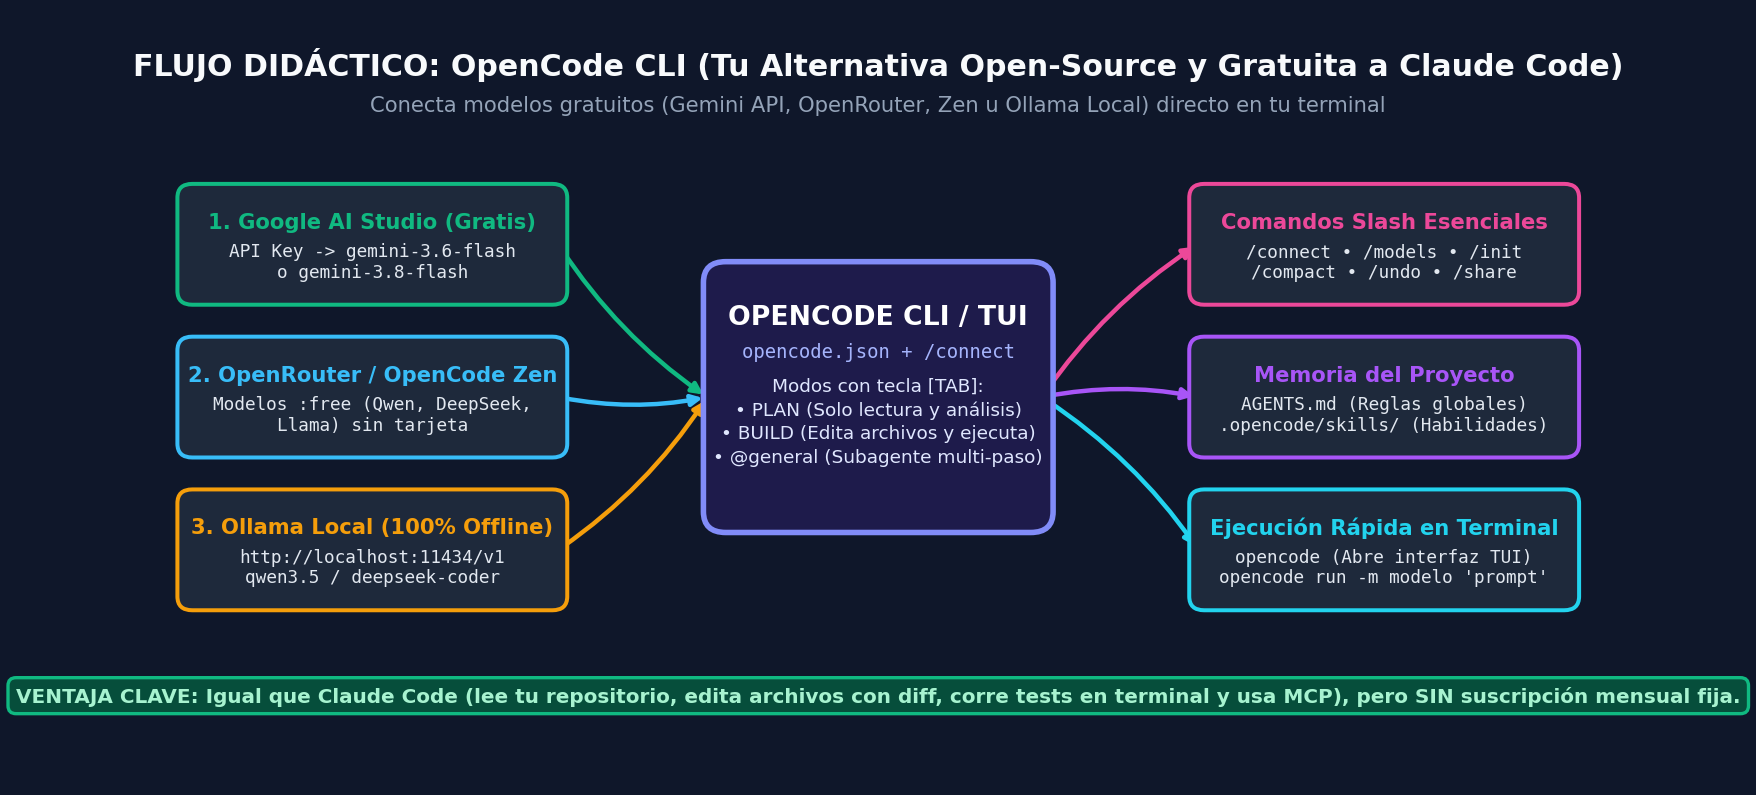

In [10]:
# 🎨 Visualización 3: Arquitectura y Flujo de Trabajo Rápido en OpenCode CLI
print("✅ Diagrama didáctico de OpenCode CLI cargado:")

### ⚡ 5.1 Instalación en 1 Comando

En tu terminal (Linux, macOS o Windows con WSL/Git Bash) o mediante gestores de paquetes ([Repositorio Oficial de OpenCode](https://github.com/anomalyco/opencode)):

```bash
# Opción A: Script oficial directo (Linux / macOS / WSL)
curl -fsSL https://opencode.ai/v2/install | bash

# Opción B: Con Node.js (npm / bun / pnpm) en cualquier sistema operativo (incluido Windows)
npm i -g @opencode/cli@latest
```

---

### 🔑 5.2 Cómo Conectarlo Gratis con Google Gemini API (En 2 Pasos)

Tienes dos formas súper rápidas de vincular tu clave gratuita de [Google AI Studio](https://aistudio.google.com/apikey) con OpenCode ([Configuración de Google Gemini en OpenCode](https://javascript.plainenglish.io/pointing-opencode-to-google-gemini-featuring-gemini-3-6-flash-513dfbf296d8)):

#### Método A: Desde la interfaz interactiva (El más rápido)
1. Abre tu terminal en la carpeta de tu proyecto y escribe `opencode` (o ejecuta `opencode auth login` desde la consola).
2. Dentro de OpenCode, escribe el comando `/connect`.
3. Selecciona **Google** (o *Other* para el endpoint compatible con OpenAI) y pega tu `API_KEY` de Google AI Studio.
4. Escribe `/models` y elige **`google/gemini-3.6-flash`**, **`google/gemini-3.8-flash`** o **`google/gemini-3.5-flash-lite`**.

#### Método B: Archivo `opencode.json` Listo para Usar ("Plug & Play")
Si prefieres dejarlo configurado de forma permanente en tu proyecto o globalmente en `~/.config/opencode/opencode.json`, OpenCode soporta el endpoint oficial de compatibilidad de Gemini ([Use Gemini in OpenCode Setup Guide](https://www.developersdigest.tech/setup/google/opencode)) y la configuración nativa ([OpenCode Config Docs](https://open-code.ai/en/docs/config)).

Ejecuta la siguiente celda de Python si deseas **generar automáticamente tu archivo `opencode.json`** listo para usar:

In [11]:
# 🛠️ Generador Rápido de Configuración `opencode.json` para usar modelos gratuitos
# Solo cambia el modelo por defecto en MODELO_OPENCODE si lo deseas:
MODELO_OPENCODE = "gemini-openai/gemini-3.6-flash"

config_opencode = {
    "$schema": "https://opencode.ai/config.json",
    "model": MODELO_OPENCODE,
    "small_model": "gemini-openai/gemini-3.5-flash-lite",
    "default_agent": "build",
    "provider": {
        "gemini-openai": {
            "npm": "@ai-sdk/openai-compatible",
            "name": "Google Gemini (Free Tier)",
            "options": {
                "baseURL": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "apiKey": "{env:GEMINI_API_KEY}"
            },
            "models": {
                "gemini-3.8-flash": {"name": "Gemini 3.8 Flash (Agentes y Código)"},
                "gemini-3.6-flash": {"name": "Gemini 3.6 Flash (Uso Diario Rápido)"},
                "gemini-3.5-flash-lite": {"name": "Gemini 3.5 Flash-Lite (Ultra Rápido)"},
                "gemini-2.5-flash-lite": {"name": "Gemini 2.5 Flash-Lite (Cuota Amplia)"}
            }
        }
    }
}

print("📄 Contenido listo para guardar como `opencode.json` en la raíz de tu proyecto:\n")
print(json.dumps(config_opencode, indent=2, ensure_ascii=False))

📄 Contenido listo para guardar como `opencode.json` en la raíz de tu proyecto:

{
  "$schema": "https://opencode.ai/config.json",
  "model": "gemini-openai/gemini-3.6-flash",
  "small_model": "gemini-openai/gemini-3.5-flash-lite",
  "default_agent": "build",
  "provider": {
    "gemini-openai": {
      "npm": "@ai-sdk/openai-compatible",
      "name": "Google Gemini (Free Tier)",
      "options": {
        "baseURL": "https://generativelanguage.googleapis.com/v1beta/openai/",
        "apiKey": "{env:GEMINI_API_KEY}"
      },
      "models": {
        "gemini-3.8-flash": {
          "name": "Gemini 3.8 Flash (Agentes y Código)"
        },
        "gemini-3.6-flash": {
          "name": "Gemini 3.6 Flash (Uso Diario Rápido)"
        },
        "gemini-3.5-flash-lite": {
          "name": "Gemini 3.5 Flash-Lite (Ultra Rápido)"
        },
        "gemini-2.5-flash-lite": {
          "name": "Gemini 2.5 Flash-Lite (Cuota Amplia)"
        }
      }
    }
  }
}


---

### 🧭 5.3 Guía Rápida de Uso Diario en OpenCode (Chuleta de Comandos)

Una vez dentro de tu proyecto ejecutando `opencode` (o `opencode web` si prefieres abrirlo en el navegador, según la [Guía de Configuración de OpenCode](https://blog.damavis.com/en/opencode-step-by-step-installation-and-configuration/)), así se trabaja a máxima velocidad:

| Acción / Tecla / Comando | ¿Para qué sirve? (Equivalencia con Claude Code) |
| :--- | :--- |
| **`Tab` (Tecla Tabulador)** | Cambia al instante entre los dos agentes principales ([OpenCode README](https://github.com/anomalyco/opencode)):<br>• **`plan` (Modo Lectura/Arquitecto):** Analiza el código y diseña un plan **sin modificar ningún archivo**.<br>• **`build` (Modo Constructor):** Crea y edita archivos, instala paquetes y ejecuta pruebas en la terminal. |
| **`/init`** | Escanea tu proyecto actual y genera automáticamente el archivo **`AGENTS.md`** (equivalente al `CLAUDE.md`), donde se guardan las reglas de estilo, arquitectura y comandos de test de tu repositorio. |
| **`@ruta/archivo.py`** | Menciona un archivo o carpeta específica en tu prompt para darle contexto quirúrgico al agente sin gastar tokens extra. |
| **`@general`** | Invoca al subagente general interno para búsquedas complejas de varios pasos dentro del proyecto ([OpenCode Docs](https://github.com/anomalyco/opencode)). |
| **`/connect` y `/models`** | Agrega nuevas claves API (Google, OpenCode Zen, OpenRouter, Ollama) y cambia de modelo en caliente sin reiniciar la sesión. |
| **`/compact`** | Comprime el historial de la conversación cuando llevas mucho tiempo programando para ahorrar tokens y no topar con límites de cuota ([OpenCode Config - Compaction](https://open-code.ai/en/docs/config)). |
| **Snapshots (Revertir)** | OpenCode rastrea los cambios automáticamente; si una edición no te gusta, puedes deshacerla y volver al estado anterior con un clic o comando. |
| **`opencode run -m proveedor/modelo "prompt"`** | Ejecuta una orden directa desde la terminal sin abrir la interfaz interactiva (por ejemplo: `opencode run -m google/gemini-3.6-flash "Explica qué hace main.py en 5 líneas"`). |

---

### 🏆 5.4 Flujo Recomendado de 4 Pasos para Programar Gratis sin Agotar Cuotas

1. **Inicializa el contexto una sola vez:** Entra a tu carpeta y corre `/init` para crear `AGENTS.md`.
2. **Planea con `Tab -> plan`:** Antes de pedir cambios grandes, presiona `Tab` para pasar al agente **`plan`** usando `gemini-3.6-flash` o `gemini-3.8-flash` y pregúntale: *"¿Qué archivos debemos tocar para agregar autenticación JWT?"*.
3. **Ejecuta con `Tab -> build`:** Cuando estés de acuerdo con el plan, presiona `Tab` para pasar a **`build`** y dile: *"Aplica los cambios y corre los tests"*.
4. **Delega tareas ligeras a `small_model`:** Como vimos en el `opencode.json` superior, asigna `gemini-3.5-flash-lite` o `gemini-2.5-flash-lite` como `small_model` para que los títulos y resúmenes internos no consuman las peticiones por minuto de tu modelo principal.